<!-- open-in-badges -->
[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/EAFIT-IA/si7011-DeepLearning/blob/main/sessions/06_foundation_models/notebooks/sesion_06_5_adaptacion.ipynb) [![Abrir en Kaggle](https://kaggle.com/static/images/open-in-kaggle.svg)](https://kaggle.com/kernels/welcome?src=https://github.com/EAFIT-IA/si7011-DeepLearning/blob/main/sessions/06_foundation_models/notebooks/sesion_06_5_adaptacion.ipynb) [![Abrir en Lightning Studio](https://pl-bolts-doc-images.s3.us-east-2.amazonaws.com/app-2/studio-badge.svg)](https://lightning.ai/new?repo_url=https%3A%2F%2Fgithub.com%2FEAFIT-IA%2Fsi7011-DeepLearning%2Fblob%2Fmain%2Fsessions%2F06_foundation_models%2Fnotebooks%2Fsesion_06_5_adaptacion.ipynb)

# SI7011 · Sesión 06 · 5. Un BERT preentrenado: congelar, ajustar o LoRA
**Juan David Martínez Vargas · Universidad EAFIT**

Acompaña las **Partes 3 y 5** de las diapositivas. Primero miramos qué aprendió DistilBERT en el preentrenamiento (predicción enmascarada, diapositiva 41). Después lo usamos de tres formas para clasificar reseñas de IMDB con **solo 2 000 ejemplos**, contra una LSTM entrenada desde cero con la receta de la sesión 05.

| Sección | Lo que cambia | Qué mirar |
|---|---|---|
| 1 | DistilBERT completa `[MASK]` | qué sabe sin haber visto IMDB |
| 2 | "bank" en tres frases | la entrada es la misma; la salida depende del contexto |
| 3 | IMDB: 2 000 reseñas para entrenar | cuántas se recortan a 256 tokens |
| 4 | LSTM desde cero | la referencia |
| 5 | encoder congelado + sonda | unos 1 500 parámetros entrenables |
| 6 | ajuste completo | los 66 millones |
| 7 | LoRA en $W_Q$ y $W_V$ | 0.2 % de los parámetros |
| 8 | la tabla | exactitud, parámetros, tiempo y memoria |

Las cuatro estrategias usan **los mismos tokens, los mismos datos y el mismo loop**; lo único que cambia entre ellas es qué parámetros tienen `requires_grad` (diapositiva 62).

**Usa GPU** (Kaggle T4, unos 10 minutos en total). En Kaggle activa **Internet** en *Settings*: DistilBERT e IMDB se bajan de Hugging Face. Sin Internet, agrega el dataset `lakshmi25npathi/imdb-dataset-of-50k-movie-reviews` con *Add Input* (el modelo sí necesita Internet).

In [1]:
# Kaggle trae torchao 0.10, que las versiones recientes de transformers y peft rechazan al importarse
# ("Found an incompatible version of torchao"). Este notebook no lo usa: si es viejo, se desinstala.
import os
from importlib.metadata import version, PackageNotFoundError
try:
    if tuple(int(x) for x in version('torchao').split('.')[:2]) < (0, 16):
        os.system('pip uninstall -y -q torchao')
except (PackageNotFoundError, ValueError):
    pass

import json, math, os, random, time, textwrap
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
import torch.nn.functional as F

try:
    import transformers, datasets, peft
except ImportError:                                         # Kaggle y Colab traen casi todo; peft a veces no
    os.system('pip install -q transformers datasets peft')
    import transformers, datasets, peft
from transformers import AutoTokenizer, AutoModel, AutoModelForMaskedLM
from datasets import load_dataset
from peft import LoraConfig, get_peft_model

random.seed(0); torch.manual_seed(0)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
dev = 'cuda' if torch.cuda.is_available() else 'cpu'
print('PyTorch', torch.__version__, '· transformers', transformers.__version__, '· peft', peft.__version__, '·', dev)
if dev == 'cpu':
    print('Sin GPU: el notebook usa pocos ejemplos. En Kaggle: Settings → Accelerator → GPU T4.')
MODELO = 'distilbert-base-uncased'      # 6 bloques, d = 768, preentrenado con predicción enmascarada

PyTorch 2.11.0+cu128 · transformers 5.16.1 · peft 0.20.0 · cuda


## 1. Lo que aprendió en el preentrenamiento
DistilBERT es un encoder de 6 bloques, $d = 768$, preentrenado en inglés (libros y Wikipedia) **ocultando el 15 % de los tokens y prediciéndolos con el contexto de ambos lados** (diapositivas 41–42). Nadie le dio etiquetas. Pidámosle que complete `[MASK]`.

**Predice antes de correr:** ¿sabe qué adjetivos van con *movie*? ¿Sabe geografía?

In [2]:
tok = AutoTokenizer.from_pretrained(MODELO)
mlm = AutoModelForMaskedLM.from_pretrained(MODELO).to(dev).eval()

@torch.no_grad()
def completar(frase, k=5):
    x = tok(frase, return_tensors='pt').to(dev)
    i = (x['input_ids'][0] == tok.mask_token_id).nonzero()[0, 0]
    p = mlm(**x).logits[0, i].softmax(-1)
    top = p.topk(k)
    return [(tok.decode([int(j)]), float(v)) for v, j in zip(top.values, top.indices)]

for frase in ['the movie was absolutely [MASK].',
              'i fell asleep because the film was so [MASK].',
              'the acting was great, but the [MASK] was terrible.',
              'paris is the capital of [MASK].']:
    print(f'{frase:<52}', ' · '.join(f'{w} {p:.2f}' for w, p in completar(frase)))

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

the movie was absolutely [MASK].                     fantastic 0.11 · fabulous 0.07 · successful 0.05 · perfect 0.03 · spectacular 0.03
i fell asleep because the film was so [MASK].        bad 0.06 · boring 0.05 · scary 0.04 · awful 0.03 · short 0.03
the acting was great, but the [MASK] was terrible.   writing 0.07 · cinematography 0.06 · timing 0.04 · editing 0.04 · lighting 0.03
paris is the capital of [MASK].                      france 0.49 · martinique 0.10 · algeria 0.04 · haiti 0.03 · brittany 0.02


Para predecir la palabra oculta tuvo que aprender gramática (después de *was so* va un adjetivo), algo del sentimiento (*fell asleep* va con *boring*) y hechos que el texto repite. Es lo que la diapositiva 49 llama "lo que aprende el preentrenamiento": todo eso está guardado en sus pesos antes de ver una sola reseña.

## 2. La misma palabra, tres vectores
La figura del comienzo de la sesión (F01), con un modelo entrenado: *bank* en un río, en un banco donde se deposita dinero y en un banco que sube las tasas. A la entrada, *bank* es la **misma fila** de la tabla $E$ en las tres frases; a la salida del último bloque, la autoatención ya mezcló el contexto.

In [3]:
enc = mlm.base_model if hasattr(mlm, 'base_model') else mlm.distilbert

@torch.no_grad()
def vector(frase, palabra):
    """Entrada (embedding de token) y salida (último bloque) de `palabra` dentro de `frase`."""
    x = tok(frase, return_tensors='pt').to(dev)
    i = x['input_ids'][0].tolist().index(tok.convert_tokens_to_ids(palabra))
    entrada = enc.embeddings.word_embeddings(x['input_ids'])[0, i]
    salida = enc(**x).last_hidden_state[0, i]
    return entrada, salida

frases = ['i sat on the bank of the river.', 'i deposited money at the bank.', 'the bank raised its interest rates.']
v = [vector(f, 'bank') for f in frases]
cos = lambda a, b: F.cosine_similarity(a, b, dim=0).item()
print('"bank" en tres frases · similitud coseno')
print(f'  entrada (tabla E):  río–dinero {cos(v[0][0], v[1][0]):.2f} · dinero–intereses {cos(v[1][0], v[2][0]):.2f}')
print(f'  salida  (bloque 6): río–dinero {cos(v[0][1], v[1][1]):.2f} · dinero–intereses {cos(v[1][1], v[2][1]):.2f}')
del mlm, enc
if dev == 'cuda':
    torch.cuda.empty_cache()

"bank" en tres frases · similitud coseno
  entrada (tabla E):  río–dinero 1.00 · dinero–intereses 1.00
  salida  (bloque 6): río–dinero 0.66 · dinero–intereses 0.87


A la entrada la similitud es exactamente 1. A la salida, los dos usos financieros quedan más cerca entre sí que del río. Por eso tiene sentido usar las **salidas** de BERT como representación (sección 5) y no los embeddings de entrada.

## 3. Los datos
IMDB: reseñas de películas en inglés, positivas o negativas (la sesión 05). Tomamos solo **2 000** para entrenar, 500 para validar y 2 000 de test: con pocas etiquetas es donde el preentrenamiento debería notarse. Los tokens son los de DistilBERT (WordPiece, minúsculas, $\lvert V\rvert \approx 30\,000$) para **todos** los modelos, también la LSTM.

In [4]:
ROOTS = [Path('.'), Path('data'), Path('/kaggle/input'), Path('/teamspace/studios/this_studio/data')]

def buscar(*patrones):
    for d in ROOTS:
        for patron in patrones:
            hits = sorted(d.glob(f'**/{patron}')) if d.exists() else []
            if hits:
                return hits[0]
    return None

def cargar_imdb():
    try:
        ds = load_dataset('stanfordnlp/imdb')
        return list(ds['train']['text']), list(ds['train']['label']), list(ds['test']['text']), list(ds['test']['label']), 'Hugging Face'
    except Exception as e:
        ruta = buscar('IMDB Dataset.csv')
        if ruta is None:
            raise RuntimeError('Sin IMDB: en Kaggle activa Internet en Settings, o agrega el dataset '
                               'lakshmi25npathi/imdb-dataset-of-50k-movie-reviews con Add Input.') from e
        df = pd.read_csv(ruta).sample(frac=1, random_state=0)
        y = (df['sentiment'] == 'positive').astype(int).tolist()
        t = df['review'].tolist()
        return t[:25000], y[:25000], t[25000:], y[25000:], f'archivo local ({ruta})'

tr_x, tr_y, te_x, te_y, fuente = cargar_imdb()
N_TRAIN, N_VAL, N_TEST = (2000, 500, 2000) if dev == 'cuda' else (64, 32, 64)
rng = random.Random(0)
i_tr = rng.sample(range(len(tr_x)), N_TRAIN + N_VAL)
i_te = rng.sample(range(len(te_x)), N_TEST)
limpiar = lambda s: s.replace('<br />', ' ')
X = {'train': [limpiar(tr_x[i]) for i in i_tr[:N_TRAIN]], 'val': [limpiar(tr_x[i]) for i in i_tr[N_TRAIN:]],
     'test': [limpiar(te_x[i]) for i in i_te]}
Y = {'train': torch.tensor([tr_y[i] for i in i_tr[:N_TRAIN]]), 'val': torch.tensor([tr_y[i] for i in i_tr[N_TRAIN:]]),
     'test': torch.tensor([te_y[i] for i in i_te])}
print(f'fuente: {fuente} · ' + ' · '.join(f'{k} {len(v)} ({Y[k].float().mean():.0%} positivas)' for k, v in X.items()))
print('\n', textwrap.shorten(X['train'][0], 300), '→', 'positiva' if Y['train'][0] else 'negativa')

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

fuente: Hugging Face · train 2000 (50% positivas) · val 500 (53% positivas) · test 2000 (50% positivas)

 FUTZ is the only show preserved from the experimental theatre movement in New York in the 1960s (the origins of Off Off Broadway). Though it's not for everyone, it is a genuinely brilliant, darkly funny, even more often deeply disturbing tale about love, sex, personal liberty, and revenge, a [...] → positiva


In [5]:
MAX_LEN = 256 if dev == 'cuda' else 128
T = {k: tok(v, truncation=True, max_length=MAX_LEN, padding='max_length', return_tensors='pt') for k, v in X.items()}
largos = [len(tok(t)['input_ids']) for t in X['train']]
print(f'tokens por reseña: mediana {int(np.median(largos))} · {np.mean(np.array(largos) > MAX_LEN):.0%} se recortan a {MAX_LEN}')
print(tok.convert_ids_to_tokens(T['train']['input_ids'][0][:24].tolist()))

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (597 > 512). Running this sequence through the model will result in indexing errors


tokens por reseña: mediana 214 · 39% se recortan a 256
['[CLS]', 'fu', '##tz', 'is', 'the', 'only', 'show', 'preserved', 'from', 'the', 'experimental', 'theatre', 'movement', 'in', 'new', 'york', 'in', 'the', '1960s', '(', 'the', 'origins', 'of', 'off']


`[CLS]` va al comienzo de cada reseña: su salida es la que usa la cabeza de clasificación (diapositiva 64). Las reseñas largas se recortan a 256 tokens: el tokenizador y el largo máximo son parte del contrato del modelo (diapositiva 75).

## 4. La referencia: una LSTM desde cero
El loop del curso (AdamW, warmup y coseno, clipping, precisión mixta), que usan los cuatro modelos. Primero la LSTM bidireccional de la sesión 05, sin preentrenamiento: todos sus pesos empiezan al azar.

In [6]:
def evaluar(modelo, parte, B=64):
    modelo.eval()
    pred = []
    with torch.no_grad():
        for i in range(0, len(Y[parte]), B):
            ids = T[parte]['input_ids'][i:i + B].to(dev); att = T[parte]['attention_mask'][i:i + B].to(dev)
            with torch.autocast('cuda', dtype=torch.float16, enabled=dev == 'cuda'):
                pred.append(modelo(ids, att).argmax(-1).cpu())
    pred = torch.cat(pred)
    return (pred == Y[parte]).float().mean().item(), pred

def entrenar(modelo, lr, epocas, B=16, nombre=''):
    """El loop del curso. Lo único que cambia entre estrategias: qué parámetros tienen requires_grad."""
    params = [p for p in modelo.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=lr, weight_decay=0.01)
    pasos = epocas * math.ceil(N_TRAIN / B)
    warm = max(1, pasos // 10)
    factor = lambda s: (s + 1) / warm if s < warm else 0.5 * (1 + math.cos(math.pi * (s - warm) / max(1, pasos - warm)))
    sched = torch.optim.lr_scheduler.LambdaLR(opt, factor)
    escalador = torch.amp.GradScaler('cuda', enabled=dev == 'cuda')
    if dev == 'cuda':
        torch.cuda.reset_peak_memory_stats()
    t0 = time.time()
    for ep in range(epocas):
        modelo.train()
        perm = torch.randperm(N_TRAIN)
        for i in range(0, N_TRAIN, B):
            j = perm[i:i + B]
            ids = T['train']['input_ids'][j].to(dev); att = T['train']['attention_mask'][j].to(dev)
            with torch.autocast('cuda', dtype=torch.float16, enabled=dev == 'cuda'):
                loss = F.cross_entropy(modelo(ids, att).float(), Y['train'][j].to(dev))
            opt.zero_grad(set_to_none=True)
            escalador.scale(loss).backward()
            escalador.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(params, 1.0)
            escalador.step(opt); escalador.update(); sched.step()
        print(f'{nombre} · época {ep + 1}/{epocas} · pérdida {loss.item():.3f} · val {evaluar(modelo, "val")[0]:.3f} · '
              f'{time.time() - t0:.0f} s')
    return fila(nombre, modelo, time.time() - t0)

def fila(nombre, modelo, segundos, entrenables=None):
    acc_val, _ = evaluar(modelo, 'val')
    acc_test, pred = evaluar(modelo, 'test')
    PRED[nombre] = pred
    return {'modelo': nombre, 'acc_val': acc_val, 'acc_test': acc_test,
            'entrenables': entrenables or sum(p.numel() for p in modelo.parameters() if p.requires_grad),
            'total': sum(p.numel() for p in modelo.parameters()), 'segundos': segundos,
            'memoria_gb': torch.cuda.max_memory_allocated() / 2**30 if dev == 'cuda' else float('nan')}

PRED, R = {}, []

In [7]:
class LSTMTexto(nn.Module):
    """La receta de la sesión 05, con los mismos tokens: embedding, LSTM bidireccional, promedio con máscara."""
    def __init__(self, V, d=128, h=128):
        super().__init__()
        self.E = nn.Embedding(V, d, padding_idx=tok.pad_token_id)
        self.lstm = nn.LSTM(d, h, batch_first=True, bidirectional=True)
        self.salida = nn.Sequential(nn.Dropout(0.3), nn.Linear(2 * h, 2))

    def forward(self, ids, att):
        H, _ = self.lstm(self.E(ids))
        m = att.unsqueeze(-1).to(H.dtype)
        return self.salida((H * m).sum(1) / m.sum(1))

torch.manual_seed(0)
R.append(entrenar(LSTMTexto(len(tok)).to(dev), lr=2e-3, epocas=8, B=32, nombre='LSTM desde cero'))

LSTM desde cero · época 1/8 · pérdida 0.670 · val 0.638 · 2 s
LSTM desde cero · época 2/8 · pérdida 0.312 · val 0.774 · 3 s
LSTM desde cero · época 3/8 · pérdida 0.577 · val 0.724 · 3 s
LSTM desde cero · época 4/8 · pérdida 0.087 · val 0.766 · 4 s
LSTM desde cero · época 5/8 · pérdida 0.021 · val 0.766 · 4 s
LSTM desde cero · época 6/8 · pérdida 0.002 · val 0.762 · 5 s
LSTM desde cero · época 7/8 · pérdida 0.011 · val 0.770 · 5 s
LSTM desde cero · época 8/8 · pérdida 0.013 · val 0.768 · 6 s


## 5. Encoder congelado + sonda
Diapositiva 64: pasamos los datos **una vez** por el encoder, guardamos $\mathbf h$ (la salida de `[CLS]`) y entrenamos solo una capa lineal sobre esos vectores, como las sondas de la sesión 04. El encoder no recibe gradiente.

**Predice** (diapositiva 76): ordena las cuatro estrategias por exactitud y por parámetros entrenables. ¿Coinciden los dos órdenes?

In [8]:
class Clasificador(nn.Module):
    """Un encoder preentrenado y una cabeza lineal sobre la salida del token [CLS] (diapositiva 64)."""
    def __init__(self, encoder):
        super().__init__()
        self.encoder = encoder
        self.cabeza = nn.Sequential(nn.Dropout(0.1), nn.Linear(encoder.config.hidden_size, 2))

    def h(self, ids, att):
        return self.encoder(input_ids=ids, attention_mask=att).last_hidden_state[:, 0]

    def forward(self, ids, att):
        return self.cabeza(self.h(ids, att))

def nuevo_encoder():
    torch.manual_seed(0)
    return AutoModel.from_pretrained(MODELO).to(dev)

In [9]:
modelo = Clasificador(nuevo_encoder()).to(dev)
for p in modelo.encoder.parameters():
    p.requires_grad_(False)                                 # el encoder no se mueve
if dev == 'cuda':
    torch.cuda.reset_peak_memory_stats()
t0 = time.time()
H = {}
with torch.no_grad():                                       # una sola pasada por los datos: h queda en caché
    modelo.encoder.eval()
    for parte in ('train', 'val', 'test'):
        hs = []
        for i in range(0, len(Y[parte]), 64):
            ids = T[parte]['input_ids'][i:i + 64].to(dev); att = T[parte]['attention_mask'][i:i + 64].to(dev)
            with torch.autocast('cuda', dtype=torch.float16, enabled=dev == 'cuda'):
                hs.append(modelo.h(ids, att).float())
        H[parte] = torch.cat(hs)
t_feat = time.time() - t0
print(f'features: {tuple(H["train"].shape)} en {t_feat:.0f} s')

sonda = nn.Linear(H['train'].shape[1], 2).to(dev)          # la cabeza, entrenada sobre los h en caché
opt = torch.optim.AdamW(sonda.parameters(), lr=1e-3, weight_decay=1e-2)
for paso in range(300):
    loss = F.cross_entropy(sonda(H['train']), Y['train'].to(dev))
    opt.zero_grad(); loss.backward(); opt.step()
modelo.cabeza[1].load_state_dict(sonda.state_dict())        # la sonda es la cabeza del clasificador
R.append(fila('DistilBERT congelado + sonda', modelo, time.time() - t0,
              entrenables=sum(p.numel() for p in sonda.parameters())))
print(R[-1])
del modelo, H

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


features: (2000, 768) en 7 s
{'modelo': 'DistilBERT congelado + sonda', 'acc_val': 0.8420000076293945, 'acc_test': 0.8424999713897705, 'entrenables': 1538, 'total': 66364418, 'segundos': 6.902514457702637, 'memoria_gb': 2.075655937194824}


## 6. Ajuste completo
Diapositiva 65: todos los pesos entrenables, con la tasa de aprendizaje **pequeña** de la sesión 03 ($3 \cdot 10^{-5}$), warmup y pocas épocas. La cabeza empieza al azar; el warmup evita que sus primeros gradientes grandes desordenen el encoder.

In [10]:
modelo = Clasificador(nuevo_encoder()).to(dev)             # todo entrenable
R.append(entrenar(modelo, lr=3e-5, epocas=3, nombre='DistilBERT ajustado completo'))
del modelo
if dev == 'cuda':
    torch.cuda.empty_cache()

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


DistilBERT ajustado completo · época 1/3 · pérdida 0.647 · val 0.880 · 14 s
DistilBERT ajustado completo · época 2/3 · pérdida 0.015 · val 0.880 · 28 s
DistilBERT ajustado completo · época 3/3 · pérdida 0.013 · val 0.876 · 42 s


## 7. LoRA
Diapositiva 66, ahora con la librería `peft`: congela el encoder y agrega $BA_r$ con $r = 8$ a $W_Q$ y $W_V$ (`q_lin`, `v_lin`) de los 6 bloques. La cabeza es nueva y también entrena. Como $B$ empieza en cero, el primer paso parte exactamente del modelo preentrenado. La tasa es más alta que en el ajuste completo: se entrenan pocos parámetros, que empiezan en cero.

In [13]:
cfg_lora = LoraConfig(r=8, lora_alpha=16, lora_dropout=0.1, target_modules=['q_lin', 'v_lin'])   # W_Q y W_V
enc_lora = get_peft_model(nuevo_encoder(), cfg_lora)       # congela el encoder y agrega B A_r
enc_lora.print_trainable_parameters()
modelo = Clasificador(enc_lora).to(dev)                     # la cabeza nueva sí entrena
R.append(entrenar(modelo, lr=5e-4, epocas=3, nombre='DistilBERT + LoRA'))
d = modelo.encoder.config.hidden_size
print(f'por matriz: 2dr = {2 * d * 8:,} contra d² = {d * d:,}')
del modelo

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


trainable params: 147,456 || all params: 66,510,336 || trainable%: 0.2217
DistilBERT + LoRA · época 1/3 · pérdida 0.569 · val 0.864 · 10 s
DistilBERT + LoRA · época 2/3 · pérdida 0.188 · val 0.868 · 21 s
DistilBERT + LoRA · época 3/3 · pérdida 0.450 · val 0.878 · 31 s
por matriz: 2dr = 12,288 contra d² = 589,824


## 8. La tabla
Exactitud en **test** (se mira una sola vez, al final), parámetros entrenables, tiempo de entrenamiento y memoria pico de la GPU (diapositiva 75).

                              acc_val  acc_test  entrenables  % entrenable  segundos  memoria_gb
modelo                                                                                          
LSTM desde cero                 0.768     0.776      4171522       100.000     5.552       0.241
DistilBERT congelado + sonda    0.842     0.842         1538         0.002     6.903       2.076
DistilBERT ajustado completo    0.876     0.891     66364418       100.000    42.150       3.385
DistilBERT + LoRA               0.878     0.889       148994         0.224    31.099       2.681


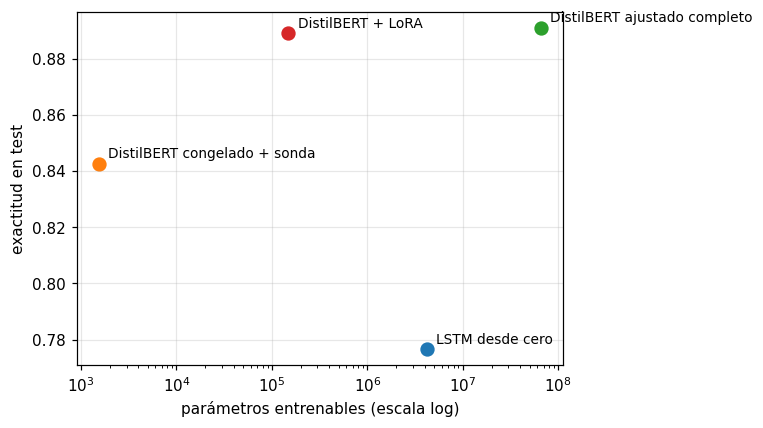

In [14]:
tabla = pd.DataFrame(R).set_index('modelo')
tabla['% entrenable'] = 100 * tabla['entrenables'] / tabla['total']
print(tabla[['acc_val', 'acc_test', 'entrenables', '% entrenable', 'segundos', 'memoria_gb']].round(3).to_string())

fig, ax = plt.subplots(figsize=(7, 4))
for nombre, r in tabla.iterrows():
    ax.scatter(r['entrenables'], r['acc_test'], s=70)
    ax.annotate(nombre, (r['entrenables'], r['acc_test']), xytext=(6, 4), textcoords='offset points', fontsize=9)
ax.set_xscale('log'); ax.set_xlabel('parámetros entrenables (escala log)'); ax.set_ylabel('exactitud en test')
plt.tight_layout(); plt.show()

Lo esperable (contrástalo con tu tabla): las tres variantes de DistilBERT superan a la LSTM con 2 000 reseñas; el ajuste completo y LoRA quedan cerca; la sonda queda detrás, con **muchísimos** menos parámetros entrenables y el menor tiempo. Los dos órdenes no coinciden: la estrategia más exacta no es la más barata, y la decisión depende de cuántas etiquetas, cuánta memoria y cuántas tareas haya (diapositiva 77).

Compara también con la sesión 05 (notebook 5.4), que entrenó con **20 000** reseñas: bolsa de embeddings 85.4 %, CNN 84.1 %, LSTM 82.6 %. Con la décima parte de las etiquetas, ¿cuáles de estos modelos las superan?

¿Dónde se equivoca la sonda y el ajuste completo no?

In [15]:
a, b = 'DistilBERT congelado + sonda', 'DistilBERT ajustado completo'
idx = [i for i in range(N_TEST) if PRED[b][i] == Y['test'][i] != PRED[a][i]]
print(f'{len(idx)} reseñas de test que el ajuste completo acierta y la sonda no. Tres:\n')
for i in idx[:3]:
    print('●', 'positiva' if Y['test'][i] else 'negativa', '·', textwrap.shorten(X['test'][i], 350), '\n')

167 reseñas de test que el ajuste completo acierta y la sonda no. Tres:

● negativa · Documentaries about fans are always mishmashes, and never worth seeing through, but I found this one, made by some of the fans themselves, more than usually unenlightening. As a veteran of the original Tolkien craze, forty years ago, I'd hoped for more than the obvious--which doesn't always equate to the true. If there's anyone living who [...] 

● negativa · Julien Hernandez is certainly an attractive and likable on screen persona. In fact, his character pretty much carries this whole film, or what's worthwhile about it. The problem is, with the exception of his gal pal (played by Marisa Petroro) and Paul Lekakis (as a trick/date/ boyfriend for some of the characters) no one else even comes [...] 

● negativa · As someone who has read all of Baroness Orczy's books and seen most of the movies based on them, I must say that the 1980's version, with Anthony Andrews and Jane Seymour, was better than this

In [16]:
json.dump({'modelo_base': MODELO, 'n_train': N_TRAIN, 'n_test': N_TEST, 'max_len': MAX_LEN, 'filas': R},
          open('resultados_adaptacion.json', 'w'), ensure_ascii=False, indent=1)
print('guardado: resultados_adaptacion.json')

guardado: resultados_adaptacion.json


## Tu turno · 10 minutos
1. **Menos etiquetas.** Repite con `N_TRAIN = 200`. ¿Cuál estrategia pierde más? ¿Y la LSTM? (Es la curva de eficiencia en etiquetas de la sesión 04.)
2. **El rango.** LoRA con `r = 2` y `r = 32`. ¿Cuántos parámetros entrenables? ¿Cambia la exactitud?
3. **Sin warmup.** En el ajuste completo, pon `warm = 1` y `lr = 1e-4`. ¿Qué le pasa a la validación en la primera época?
4. **Otra salida.** En la sonda, usa el promedio de todas las salidas (con la máscara de relleno) en lugar de `[CLS]`. ¿Mejora?

**Para pensar.** Una clínica tiene 800 notas clínicas en español y una GPU de 16 GB (la pregunta de salida). ¿Qué cambiarías de este notebook?

In [ ]:
# Tu turno

### Referencias
- Devlin et al. (2019), *BERT: Pre-training of Deep Bidirectional Transformers for Language Understanding*, NAACL.
- Sanh et al. (2019), *DistilBERT, a distilled version of BERT: smaller, faster, cheaper and lighter*.
- Hu et al. (2021), *LoRA: Low-Rank Adaptation of Large Language Models*, ICLR 2022.
- Maas et al. (2011), *Learning Word Vectors for Sentiment Analysis*, ACL (IMDB).
- Material del curso del semestre anterior (`jdmartinev/si7011-deeplearning`, `Lecture06`): los notebooks de DistilBERT sobre IMDB.